# Readmission study

Exploratory analysis of synthetic hospital admissions data. Worked example to get used to integration of SQL, python (in particular venv) and using AI coding.


## Import libraries

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().parent
sys.path.append(str(project_root))

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from datetime import date, timedelta
from src.db_config import DATABASE_URL

## Connect to database

In [3]:
engine = create_engine(DATABASE_URL)

In [4]:
STUDY_START_DATE = date(2019, 1, 1)
STUDY_END_DATE = date(2023, 12, 31)
READMISSION_WINDOW = 30

## Patient demographics

In [5]:
query = f"""
WITH reference_date AS (
    SELECT DATE '{STUDY_END_DATE}' AS reference_date
    FROM admissions
)
SELECT
    p.patient_id,
    p.sex,
    p.dob,
    r.reference_date,
    EXTRACT(YEAR FROM AGE(r.reference_date, p.dob))::INT
        AS age_at_reference_date
FROM patients AS p
CROSS JOIN reference_date AS r
ORDER BY p.patient_id
"""

In [6]:
df_demographics = pd.read_sql(query, engine)
df_demographics

,patient_id,sex,dob,reference_date,age_at_reference_date
0,1,Female,1981-05-13,2023-12-31,42
1,1,Female,1981-05-13,2023-12-31,42
2,1,Female,1981-05-13,2023-12-31,42
3,1,Female,1981-05-13,2023-12-31,42
4,1,Female,1981-05-13,2023-12-31,42
...,...,...,...,...,...
3440995,1000,Male,1986-04-05,2023-12-31,37
3440996,1000,Male,1986-04-05,2023-12-31,37
3440997,1000,Male,1986-04-05,2023-12-31,37
3440998,1000,Male,1986-04-05,2023-12-31,37


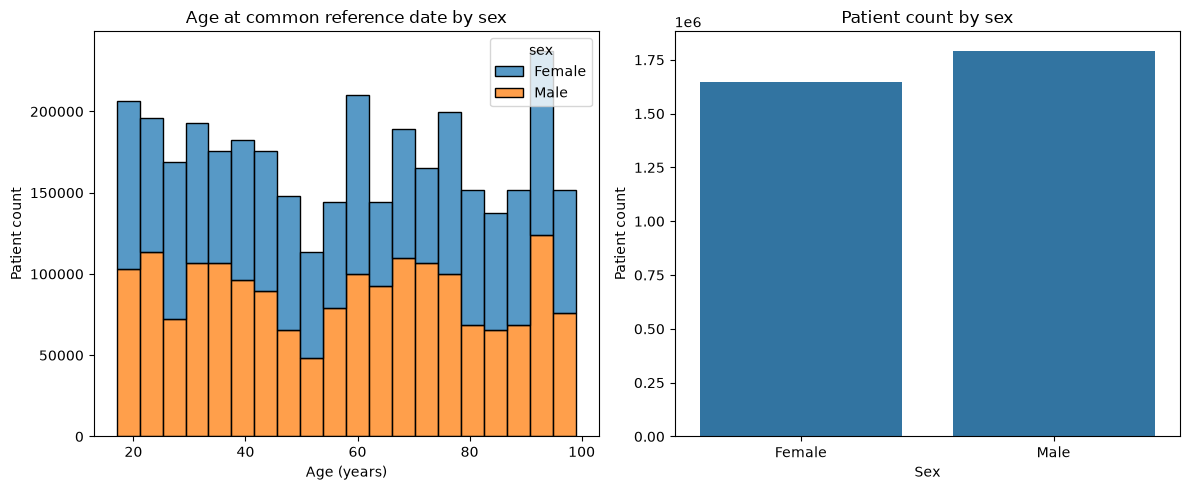

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df_demographics,
    x="age_at_reference_date",
    hue="sex",
    bins=20,
    multiple="stack",
    ax=axes[0]
)
axes[0].set_title("Age at common reference date by sex")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Patient count")

sns.countplot(data=df_demographics, x="sex", ax=axes[1])
axes[1].set_title("Patient count by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Patient count")

fig.tight_layout()

## Average length of stay by diagnosis

In [8]:
query = """
SELECT
    diagnosis,
    AVG(discharge_date - admission_date) AS avg_los
FROM admissions
GROUP BY diagnosis
ORDER BY avg_los DESC
"""


In [9]:
df = pd.read_sql(query, engine) 
df

,diagnosis,avg_los
0,Chest pain,7.794521
1,Sepsis,7.595442
2,Chronic obstructive pulmonary disease,7.559889
3,Hip fracture,7.527108
4,Type 2 diabetes,7.492386
5,Kidney disease,7.485549
6,Heart failure,7.468843
7,Urinary tract infection,7.366477
8,Stroke,7.293051
9,Pneumonia,7.279539


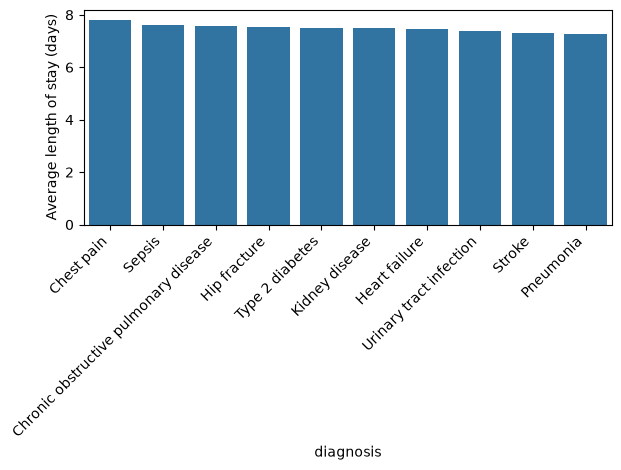

In [10]:


ax = sns.barplot(
    data=df,
    x="diagnosis",
    y="avg_los"
)
ax.set_ylabel("Average length of stay (days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## First diagnosis per patient and disease

In [11]:
first_diagnoses_query = """
WITH ranked_admissions AS (
    SELECT
        a.patient_id,
        a.diagnosis,
        a.admission_date AS first_diagnosis_date,
        p.dob,
        ROW_NUMBER() OVER (
            PARTITION BY a.patient_id, a.diagnosis
            ORDER BY a.admission_date, a.admission_id
        ) AS diagnosis_rank
    FROM admissions AS a
    JOIN patients AS p ON a.patient_id = p.patient_id
)
SELECT patient_id, diagnosis, first_diagnosis_date, dob
FROM ranked_admissions
WHERE diagnosis_rank = 1
ORDER BY patient_id, first_diagnosis_date, diagnosis
"""

In [12]:
df_first_diagnoses = pd.read_sql(first_diagnoses_query, engine)
df_first_diagnoses

,patient_id,diagnosis,first_diagnosis_date,dob
0,1,Type 2 diabetes,2019-05-18,1981-05-13
1,1,Heart failure,2019-12-30,1981-05-13
2,2,Chronic obstructive pulmonary disease,2021-04-04,1926-03-30
3,2,Type 2 diabetes,2021-05-14,1926-03-30
4,2,Heart failure,2021-09-30,1926-03-30
...,...,...,...,...
2363,1000,Pneumonia,2020-05-04,1986-04-05
2364,1000,Chronic obstructive pulmonary disease,2020-05-22,1986-04-05
2365,1000,Urinary tract infection,2021-03-24,1986-04-05
2366,1000,Sepsis,2021-04-24,1986-04-05


## Average age by first diagnosis

In [13]:
df_first_diagnoses["dob"] = pd.to_datetime(df_first_diagnoses["dob"])
df_first_diagnoses["first_diagnosis_date"] = pd.to_datetime(
    df_first_diagnoses["first_diagnosis_date"]
)

df_first_diagnoses["age_at_diagnosis"] = (
    (df_first_diagnoses["first_diagnosis_date"] - df_first_diagnoses["dob"])
    .dt.days / 365.25
) 

In [14]:
avg_age_by_first_diagnosis = (
    df_first_diagnoses.groupby("diagnosis", as_index=False)["age_at_diagnosis"]
    .mean()
    .rename(columns={"age_at_diagnosis": "avg_age"})
    .sort_values("avg_age", ascending=False)
)
avg_age_by_first_diagnosis

,diagnosis,avg_age
1,Chronic obstructive pulmonary disease,59.124606
8,Type 2 diabetes,56.826894
4,Kidney disease,56.060562
2,Heart failure,55.348637
7,Stroke,55.030729
3,Hip fracture,54.750651
0,Chest pain,54.681686
6,Sepsis,54.358998
5,Pneumonia,54.179050
9,Urinary tract infection,53.715556


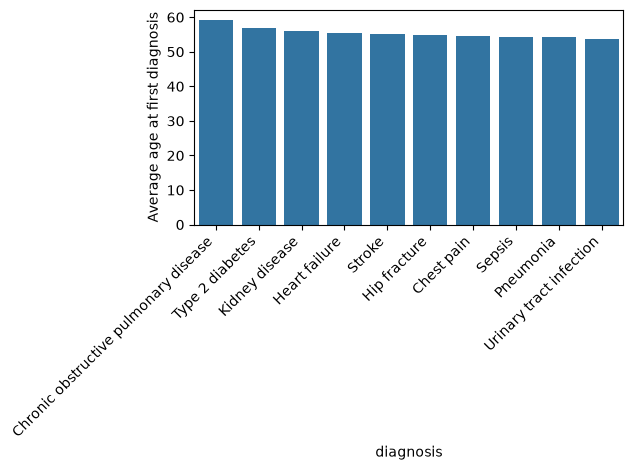

In [15]:
ax = sns.barplot(
    data=avg_age_by_first_diagnosis,
    x="diagnosis",
    y="avg_age"
)
ax.set_ylabel("Average age at first diagnosis")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## Readmission
ground truth readmission reason

In [16]:
query = """
SELECT
    readmission_reason,
    COUNT(*) AS readmission_count
FROM admissions
GROUP BY readmission_reason
ORDER BY readmission_count DESC
"""
df = pd.read_sql(query, engine) 
df

,readmission_reason,readmission_count
0,new_episode,1661
1,index_admission,830
2,unplanned_related,403
3,unplanned_unrelated,277
4,planned_follow_up,270


defining readmission as within 30 days

removing new admissions/cases that occur within 30days of the study end date

In [22]:
cutoff_date = STUDY_END_DATE - timedelta(days=READMISSION_WINDOW)

query = f"""
WITH admissions_with_prev AS (
    SELECT
        a.*,

        LAG(admission_id)   OVER w AS previous_admission_id,
        LAG(admission_date) OVER w AS previous_admission_date,
        LAG(discharge_date) OVER w AS previous_discharge_date,
        LAG(diagnosis)      OVER w AS previous_diagnosis

    FROM admissions a
    WINDOW w AS (
        PARTITION BY patient_id
        ORDER BY admission_date
    )
)

SELECT
    *,
        admission_date - previous_discharge_date AS days_since_last_discharge,
    CASE
        WHEN previous_discharge_date IS NOT NULL
         AND admission_date - previous_discharge_date <= 30
        THEN 1
        ELSE 0
    END AS readmission_30d,
    CASE
        WHEN diagnosis = previous_diagnosis
        THEN 'related'
        ELSE 'different'
    END AS diagnosis_relationship,

    CASE
        WHEN discharge_date > DATE '{cutoff_date}'
        THEN NULL
        WHEN previous_discharge_date IS NOT NULL
            AND admission_date - previous_discharge_date <= 30
        THEN 1
        ELSE 0
    END AS readmission_30d_censored
FROM admissions_with_prev AS ap
JOIN patients AS p ON ap.patient_id = p.patient_id;
"""

df = pd.read_sql(query, engine) 
df["readmission_30d"].value_counts()

readmission_30d
0    2491
1     950
Name: count, dtype: int64

In [23]:

(
    df.groupby(["previous_diagnosis"])
      .agg(
          admissions=("admission_id", "count"),
          readmission_rate=("readmission_30d_censored", "mean")
      )
      .sort_values("readmission_rate", ascending=False)
)

,admissions,readmission_rate
previous_diagnosis,,
Urinary tract infection,263,0.418972
Kidney disease,258,0.395918
Stroke,250,0.384298
Sepsis,262,0.374502
Pneumonia,269,0.353612
Type 2 diabetes,304,0.351351
Hip fracture,251,0.345528
Chronic obstructive pulmonary disease,279,0.344322
Heart failure,246,0.342975


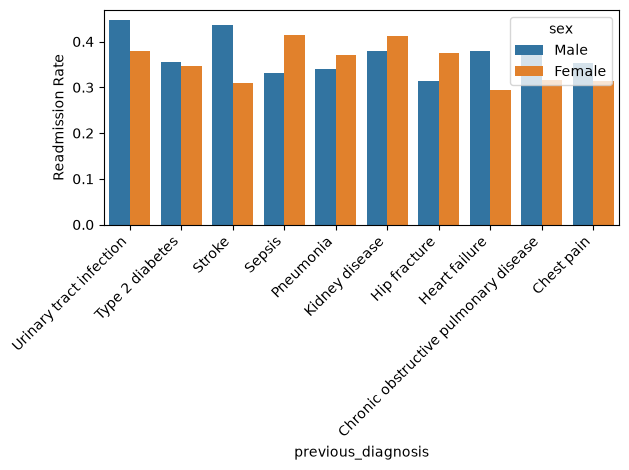

In [28]:

plot_data =(
    df.groupby(["sex","previous_diagnosis"])
      .agg(
          admissions=("admission_id", "count"),
          readmission_rate=("readmission_30d_censored", "mean")
      )
      .sort_values(["sex","previous_diagnosis"], ascending=False)
)

ax = sns.barplot(
    data=plot_data,
    x="previous_diagnosis",
    y="readmission_rate",
    hue="sex"
)
ax.set_ylabel("Readmission Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()